# F1 · Definición del proyecto

Implementación inicial del proyecto (Fase 1): problemática, objetivos y configuración del flujo de trabajo reproducible.

In [1]:
# Configuración común: rutas del proyecto y semilla reproducible.
from pipeline import config

print("Raíz del proyecto:", config.PROJECT_ROOT.name)
print("Datos originales:", config.RAW_DATA_DIR.relative_to(config.PROJECT_ROOT))

Raíz del proyecto: 002_sumativa-1-avance-proyecto-f1-y-f2-40
Datos originales: data/raw


## 1. Contexto del caso

ChileCompra, la Dirección de Compras y Contratación Pública, publica datos abiertos sobre las adquisiciones del Estado, y este estudio analiza órdenes de compra y licitaciones del sector salud en la Región de Valparaíso. El estudio compara septiembre de 2024 con septiembre de 2025. Entre ambos meses las órdenes suman aproximadamente $49.163 millones, 10.285 órdenes y 25.880 líneas de detalle con 79 variables. Las licitaciones de los mismos meses (2.726 y 2.361 filas) están descargadas y se procesarán en una fase posterior. Este volumen, la existencia de varias filas por proceso, la mezcla de monedas y los datos faltantes hacen inviable una revisión manual y exigen técnicas de análisis que eviten duplicidades y totales inflados. El tema es relevante porque involucra recursos públicos destinados a hospitales y servicios de salud, cuya transparencia, eficiencia y exposición a riesgos cobran especial importancia tras la Ley N.º 21.634, publicada el 11 de diciembre de 2023 y con una segunda etapa vigente desde diciembre de 2024 ([ChileCompra](https://www.chilecompra.cl/ley-de-compras-publicas/)).


## 2. Problemática

Queremos entender si el gasto público en salud de la Región de Valparaíso se concentra en un grupo reducido de proveedores. Para esto analizaremos las órdenes de compra de septiembre de 2024 y de septiembre de 2025, antes y después de los cambios de la Ley N.º 21.634. El tema nos interesa porque una alta concentración de proveedores puede disminuir la competencia, que la Organización para la Cooperación y el Desarrollo Económicos (OCDE, 2026) advierte que está bajo presión en muchas economías, y aumentar algunos riesgos de gestión. Mediremos qué porcentaje del monto reúnen los 10 mayores proveedores, si algunas unidades compran repetidamente a los mismos y cómo cambia la concentración según la modalidad de compra.

Desde la mirada de Niklas Luhmann, sociólogo que desarrolló la teoría de sistemas sociales, ChileCompra es un sistema organizacional con controles administrativos pensados para lograr compras eficientes y éticas. Las personas que trabajan en él se relacionan entre sí, y esa relación podría perturbar esos controles. Planteamos esta idea solo como hipótesis para interpretar los patrones, no como un hecho.

Los datos permiten ver cuánto, dónde y con qué frecuencia se concentra el gasto, pero no sus motivos. Una concentración alta tampoco prueba irregularidades, porque puede tener razones legítimas, como insumos especializados o convenios marco. Por eso no podremos demostrar vínculos entre personas ni conductas indebidas.


## 3. Preguntas centrales del análisis

**Pregunta central**

¿En qué medida el gasto en salud de la Región de Valparaíso, registrado en las órdenes de compra de septiembre de 2024 y septiembre de 2025, se concentra en pocos proveedores, y cómo cambia entre ambos períodos, organismos y modalidades de compra?


**Preguntas específicas**


1. ¿Qué porcentaje del monto total de las órdenes de compra concentran los diez principales proveedores?

2. ¿Qué unidades de compra destinan la mayor parte de su monto a uno o dos proveedores?

3. ¿Qué combinaciones de unidad de compra y proveedor se repiten con mayor frecuencia o monto?

4. ¿Existe una mayor concentración en los tratos directos y las compras ágiles que en las licitaciones, según los datos del período?

5. ¿Cómo afectan al cálculo de la concentración los datos faltantes, los montos en otras monedas y las líneas repetidas por orden?

## 4. Objetivos

Objetivo General
Analizar la concentración del gasto público en salud de la Región de Valparaíso, utilizando datos de órdenes de compra y licitaciones obtenidos desde ChileCompra, con el propósito de determinar el grado de participación de los principales proveedores, identificar patrones de dependencia entre organismos compradores y proveedores, y evaluar diferencias en la concentración según las modalidades de compra utilizadas, comparando septiembre de 2024 con septiembre de 2025, antes y después de los cambios de la Ley N.º 21.634.
________________________________________
Objetivos Específicos
OE1: Obtener, integrar y preparar los datos de órdenes de compra y licitaciones del sector salud de la Región de Valparaíso, realizando procesos de depuración, tratamiento de datos faltantes, eliminación de duplicidades y homologación de montos expresados en distintas monedas.
OE2: Cuantificar la concentración del gasto público mediante el análisis de la participación de los principales proveedores en el monto total adjudicado y en el número de procesos de compra.
OE3: Evaluar el nivel de dependencia de las distintas unidades de compra respecto de determinados proveedores, identificando relaciones recurrentes y patrones de contratación predominantes.
OE4: Comparar la concentración del gasto según las modalidades de adquisición disponibles en ChileCompra, incluyendo licitaciones, compra ágil y trato directo, para identificar diferencias en la distribución de los recursos públicos.
OE5: Detectar patrones de concentración y comportamientos atípicos en las adjudicaciones que puedan constituir indicadores de riesgo para la competencia, la diversidad de proveedores y la transparencia del sistema de compras públicas.
OE6: Interpretar los resultados obtenidos desde una perspectiva organizacional, considerando que los patrones observados pueden reflejar dinámicas propias del sistema de compras públicas, sin que ello permita inferir relaciones personales, conflictos de interés o irregularidades.


## 5. Alcance, restricciones y supuestos

> El presente proyecto se enfocará en el análisis de las órdenes de compra y licitaciones del sector salud de la Región de Valparaíso publicadas en la plataforma ChileCompra, considerando septiembre de 2024 y septiembre de 2025, congelados como conjunto de estudio.

El trabajo abarcará las fases de obtención, preparación, transformación, validación y análisis exploratorio de datos (F1 y F2), con énfasis en la medición de la concentración del gasto, la identificación de proveedores dominantes, el análisis de la dependencia de las unidades compradoras y la caracterización de patrones de contratación.

El estudio utilizará indicadores descriptivos y comparativos para examinar la distribución de los recursos públicos entre proveedores y modalidades de compra. Asimismo, se identificarán patrones recurrentes o comportamientos atípicos que puedan representar señales de concentración o potenciales riesgos para la competencia.

Sin embargo, el alcance del proyecto se limita al análisis de los datos publicados por ChileCompra. Por esta razón, los resultados permitirán describir y cuantificar patrones de gasto, pero no determinar las causas que los originan ni demostrar la existencia de vínculos personales, conflictos de interés, prácticas anticompetitivas o actos de corrupción. Estas interpretaciones exceden la información disponible y deberán ser consideradas únicamente como hipótesis para futuras investigaciones.

Supuestos

•	Los datos publicados por ChileCompra representan adecuadamente las compras realizadas por los organismos analizados.

•	Los procesos de limpieza y homologación permiten obtener indicadores comparables y consistentes.

•	La concentración del gasto constituye un indicador válido para analizar dependencia de proveedores y niveles de competencia.

•	Los patrones observados reflejan comportamientos del sistema de compras públicas, pero no permiten inferir intencionalidad ni responsabilidades individuales.

Restricciones

•	El análisis se limita al sector salud de la Región de Valparaíso.

•	Solo se consideran los datos disponibles en ChileCompra.

•	Los resultados dependen de la calidad e integridad de la información publicada.

•	La existencia de concentración no implica por sí misma una irregularidad.

•	El estudio no tiene alcance investigativo, judicial ni fiscalizador respecto de posibles actos de corrupción.



## 6. Vínculo con el mapa conceptual técnico
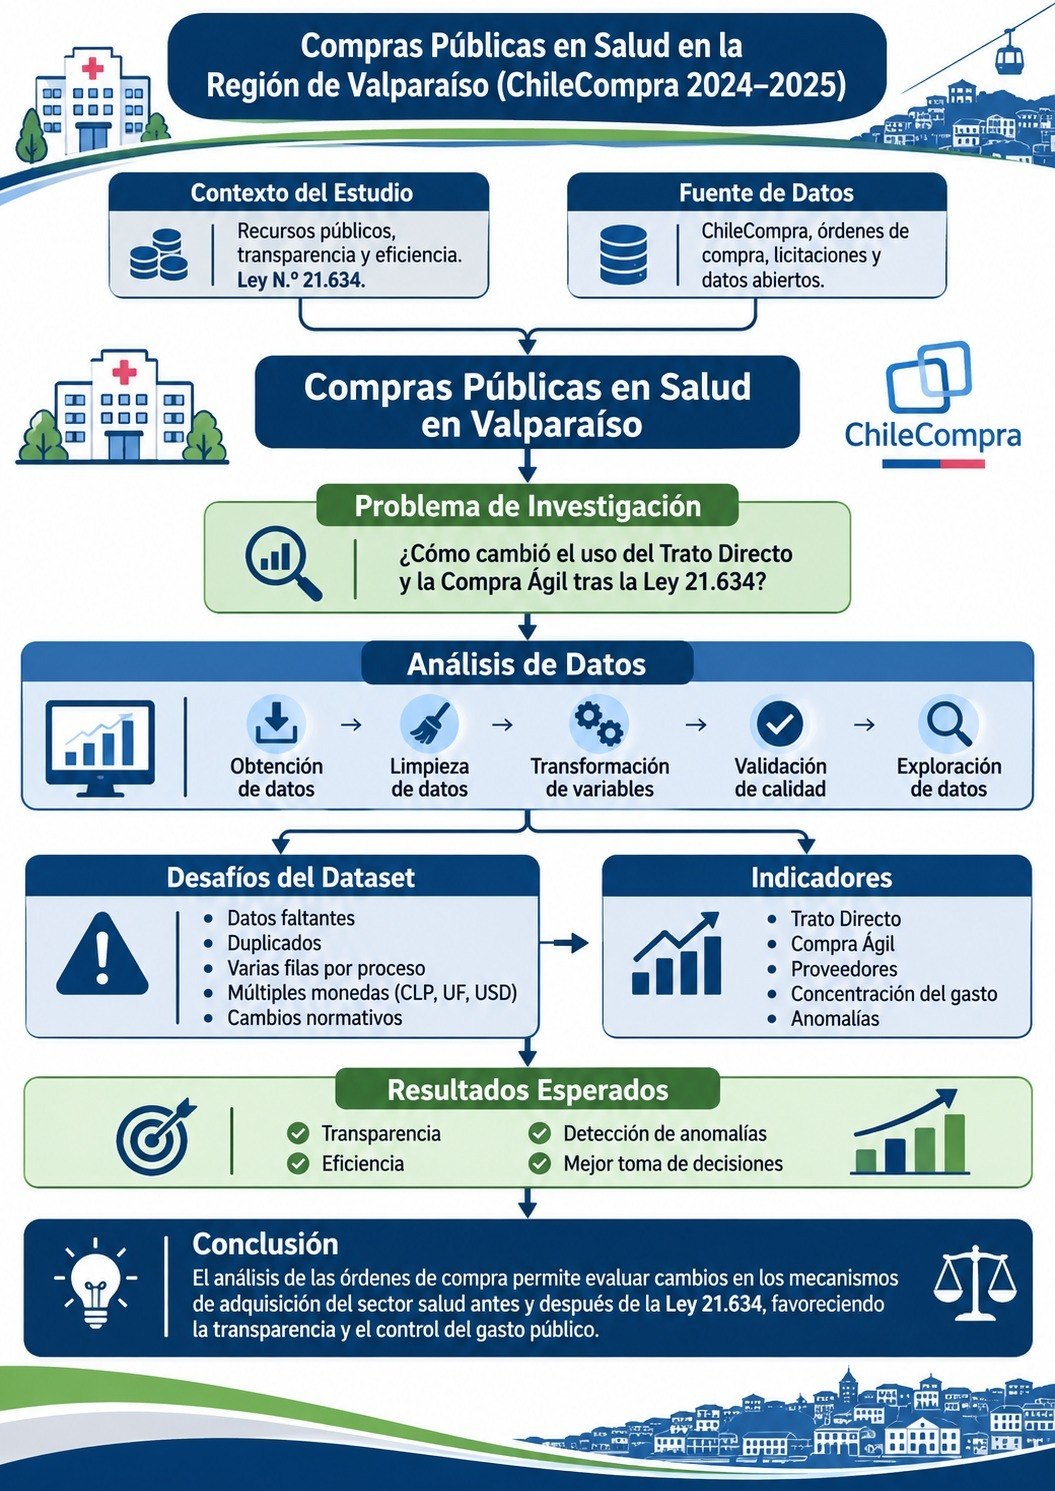


El mapa conceptual ha servido como guía para la definición y desarrollo del proyecto. La relación entre sus componentes y el avance realizado es la siguiente:
•	Contexto del estudio: Implementado en el informe y README mediante la descripción de ChileCompra, el sector salud y la Ley N.º 21.634.

•	Fuente de datos: Implementada mediante la selección y documentación de las bases de órdenes de compra y licitaciones obtenidas desde ChileCompra.

•	Problema de investigación: Implementado en F1_Definición.ipynb y en el informe, donde se define la concentración del gasto en proveedores como eje central del 
estudio.
•	Obtención de datos: Implementada mediante la descarga, almacenamiento y documentación de las bases de datos utilizadas.

•	Limpieza de datos: Implementada en `F2/03_limpieza.ipynb`. Trata los datos faltantes con una decisión por variable y revisa duplicados.

•	Transformación de variables: Implementada en `F2/04_transformacion.ipynb`. Convierte montos y fechas, crea la variable `modalidad` y deja una fila por orden.

•	Validación de calidad: Implementada en `F2/05_validacion.ipynb` y en las pruebas de `tests/`, con siete reglas de calidad y la cuadratura contra los datos originales.

•	Exploración de datos: Implementada en `F2/02_exploracion.ipynb`, que revisa tipos, datos faltantes y el cambio de definición del trato directo entre años.

•	Desafíos del dataset: Implementados en la documentación del proyecto, donde se identifican problemas como duplicados, múltiples filas por proceso, datos faltantes y diferencias de moneda.

•	Indicadores de análisis: Implementados en la planificación metodológica mediante la definición de métricas relacionadas con concentración del gasto, proveedores, organismos compradores y modalidades de compra.

•	Resultados esperados: Implementados en la formulación de objetivos, orientados a mejorar la comprensión de los patrones de gasto y apoyar la transparencia en las compras públicas.

Proyección para F3 y F4

•	F3: Desarrollo del análisis de concentración del gasto, identificación de proveedores dominantes, visualización de resultados e identificación de patrones recurrentes.

•	F4: Interpretación de resultados, elaboración de conclusiones, análisis de limitaciones y formulación de recomendaciones.

Coherencia entre planificación y desarrollo

Existe coherencia entre el mapa conceptual y las actividades desarrolladas hasta el momento. Los elementos relacionados con la problemática, las fuentes de datos y la planificación metodológica ya fueron implementados en F1, y las actividades de preparación de datos ya fueron implementadas en F2. La versión técnica del mapa, con las herramientas, el flujo y la estructura del repositorio, está en `F1/mapa-conceptual/mapa-conceptual.html`. Los análisis de concentración, visualización de resultados y conclusiones se encuentran planificados para las fases F3 y F4, respetando la estructura definida inicialmente en el mapa conceptual.



## 7. Configuración del entorno reproducible

El proyecto se ejecuta en un ambiente virtual (`.venv`) con Python 3.14 y las dependencias de `requirements.txt`, todas con versión exacta. `scripts/check_environment.py` compara lo instalado con lo fijado y deja el registro en `docs/entorno.md`. La celda siguiente muestra las versiones en uso.

In [2]:
# Versiones del entorno en que se ejecuta este notebook.
import platform

import numpy as np
import pandas as pd

print("Python", platform.python_version(), "| pandas", pd.__version__, "| NumPy", np.__version__)

Python 3.14.6 | pandas 3.1.0 | NumPy 2.5.4


## 8. Primeras operaciones técnicas

El código reutilizable vive en `src/pipeline/` y los notebooks lo importan. Como primera operación se comprueba que los datos originales no cambiaron (huella SHA-256) y se cargan las órdenes de los dos meses.

In [3]:
# Verifica la integridad de data/raw/ y carga las órdenes de ambos períodos.
from pipeline import chilecompra as cc
from pipeline import ordenes

checks = cc.verify_manifest(config.RAW_DATA_DIR, config.RAW_DATA_DIR / "manifest.json")
assert all(checks.values()), "Un archivo de data/raw/ no coincide con su huella"

raw = ordenes.load_orders(config.RAW_DATA_DIR)
raw.groupby("periodo").agg(lineas=("Codigo", "size"), ordenes=("Codigo", "nunique"))

,lineas,ordenes
periodo,,
2024-09,12025,4598
2025-09,13855,5687


## 9. Organización del repositorio y flujo Git

| Carpeta | Contenido |
|---|---|
| `F1/`, `F2/` | Notebooks de cada fase |
| `src/pipeline/` | Funciones reutilizables |
| `tests/` | Pruebas automáticas (pytest) |
| `data/raw/` | Datos originales congelados, con su manifiesto |
| `data/processed/` | Datos limpios, que se regeneran |
| `docs/` | Entorno, decisiones, validación y evidencias |
| `scripts/` | Obtención de datos, verificación y ejecución completa |

**Flujo Git:** nadie trabaja directo en `main`. Cada tarea va en una rama (`feature/…` o `docs/…`), se integra por *pull request* revisado por otro integrante y se une con *merge commit*. Los mensajes siguen la convención `tipo(alcance): descripción`.

## 10. Articulación con las fases F2–F4

| Fase | Qué aporta | Dónde |
|---|---|---|
| F2 · Datos | Obtención, exploración, limpieza, transformación y validación | `F2/01` a `F2/05` |
| F3 · Núcleo algorítmico | Cálculo de los indicadores de concentración y modalidad con clases, y medición de eficiencia | `F3/` |
| F4 · Comunicación | Visualizaciones, conclusiones e informe final | `F4/` |

El dataset que entrega la Fase 2 (`data/processed/ordenes.csv`, una fila por orden) es la entrada de la Fase 3.

## Referencias

Dirección de Compras y Contratación Pública (ChileCompra). (2026). *Órdenes de compra y licitaciones, septiembre de 2024 y septiembre de 2025* [Conjuntos de datos]. https://transparenciachc.blob.core.windows.net/oc-da/2024-9.zip y https://transparenciachc.blob.core.windows.net/oc-da/2025-9.zip


Ley 21634 de 2023. Moderniza la Ley N° 19.886 y otras leyes, para mejorar la calidad del gasto público, aumentar los estándares de probidad y transparencia e introducir principios de economía circular en las compras del Estado. 11 de diciembre de 2023. D.O. N.º 43722. https://www.bcn.cl/leychile/navegar?idNorma=1198903


Organización para la Cooperación y el Desarrollo Económicos. (2026). *Competition in public procurement*. OECD Publishing. https://www.oecd.org/en/publications/competition-in-public-procurement_fcc81703-en/full-report.html